## mlpi26_IL_nb1.ipynb

*Companion notebook for Chapter 15b, Imitation Learning and Robot Foundation Models.*

# Imitation learning for robotics: from behaviour cloning to robot foundation models

**Running example — a gantry that must thread a door.** A planar end-effector (think of a Cartesian
gantry, or a robot arm under task-space velocity control) starts below a wall and must reach a goal
above it, passing through one of two 20 cm doors. A scripted demonstrator plays the role of the human
teleoperator. We never write a reward: every policy in this notebook is learned **only from
demonstrations**, the way most real manipulation policies, including today's robot foundation models,
are trained.

### Learning objectives
By the end you should be able to

1. write imitation learning as supervised learning, and train a behaviour-cloning (BC) policy in PyTorch;
2. explain why a small per-step error grows over an episode (*compounding error, distribution shift*);
3. recognise *causal confusion*, where a lower training loss gives a worse robot;
4. fix distribution shift with DAgger and with noise injection during demonstrations (DART);
5. explain why mean-squared-error regression fails on multimodal demonstrations, and fix it with a
   mixture density network and a diffusion policy with action chunking;
6. describe how vision-language-action (VLA) robot foundation models extend these ideas, and use the
   pre-train / fine-tune recipe to adapt a policy to a new robot from a handful of demonstrations.

### Prerequisites
Python, NumPy, PyTorch (`nn.Module`, an optimiser loop — Lectures 7–8). The RL lecture (12) helps for
the comparison in §1 but is not required.

| part | method | what it teaches |
|---|---|---|
| one door, 5–50 demos | behaviour cloning | imitation = regression; compounding error |
| one door, + velocity input | behaviour cloning | causal confusion (the "copycat" problem) |
| one door, 10 demos + queries | DAgger, DART | fixing distribution shift |
| two doors, 100 demos | MSE BC, MDN, diffusion policy | multimodal demonstrations; action chunks |
| random layouts, two robots | instruction-conditioned policy | pre-training and fine-tuning, as in VLAs |

Everything is simulated, seeded and runs on a CPU with no downloads (≈ 5.5 minutes in total
on two threads).

In [1]:
import sys, time, json, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import NullFormatter

torch.set_num_threads(2)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__,
      "| matplotlib", matplotlib.__version__)

SURF, INK2, GRID = "#fcfcfb", "#52514e", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GREY = "#898781"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.axisbelow": True, "figure.dpi": 110})
R = {}                      # every number quoted in the text is stored here
T_START = time.time()

python 3.13.18 | numpy 2.5.3 | torch 2.15.0+cu132 | matplotlib 3.11.2


## 1. Why imitate?

Lecture 12 taught a quadrotor to hover with reinforcement learning. That needed two things a factory
rarely has: a **reward function** that captures the task, and **millions of trials**, which only a
simulator can supply. For "insert this connector", "fold this cable into the tray" or "pick the part
and place it in the fixture", writing the reward is as hard as writing the controller, and a crash
costs a real part.

Imitation learning (IL) asks for something cheaper: **show the robot what to do.** An operator drives
the robot with a teleoperation rig — a leader arm, a 3-D mouse, a VR controller — and we record
pairs of what the robot *observed* and what the operator *commanded*. A policy is then trained to
reproduce the operator.

| | reinforcement learning | imitation learning |
|---|---|---|
| supervision | a scalar reward | expert actions |
| data | the robot's own trials | demonstrations (usually teleoperated) |
| typical amount | 10⁵–10⁸ steps, in simulation | 10–1000 demonstrations, on the real robot |
| can beat the teacher? | yes | not by itself |
| main failure | reward hacking, sample cost | distribution shift, ambiguous demos |

The first imitation-learned robot policy predates deep learning: ALVINN (Pomerleau, 1989) steered a
van from camera images with a 3-layer network trained on a human driver. The problems Pomerleau ran
into — the network had never seen the car drift off-centre, because the human never drifted — are the
subject of §3–5.

## 2. The running example: threading a door

| design choice | value | why |
|---|---|---|
| state | position $p=(x,y)$, velocity $v$, goal $g$ | a 2-D end-effector |
| action | $u\in[-1,1]^2$, commanded velocity $v_\text{max}R\,u$ with $v_\text{max}$ = 0.5 m/s | velocity control, as for a gantry or task-space arm |
| servo | $v_{t+1} = v_t + \tfrac{\Delta t}{\tau}(v_\text{cmd} - v_t)$, $\tau$ = 0.2 s, $\Delta t$ = 0.1 s | the real axis lags the command |
| disturbance | Gaussian velocity noise, σ = 0.1 m/s per step, at test time | vibration, slip, an operator bumping the cell |
| wall | $y = 0$, 10 cm thick, doors 20 cm wide at $x = \pm 0.5$ | the precise part of the task |
| observation | $p$, $g - p$, both door positions (6 numbers) | what the policy sees; no velocity (see §3.2) |
| success | within 6 cm of the goal in 120 steps (12 s) without touching the wall | |

The **expert** is a scripted controller with a "safe-height" motion familiar from pick-and-place:
rise to a traverse line at $y=-0.35$, move sideways until under the chosen door, go straight up
through it, then head for the goal. It is written as a function of the state *and the door it chose*,
so it can tell us the right action in **any** state — the property DAgger needs in §4.

The expert succeeds in 100.0 % of episodes without disturbance and 97.5 % with it,
because it is a feedback controller and corrects drift. That is our upper bound.

In [2]:
class DoorReach:
    '''Planar end-effector (a Cartesian gantry, or an arm under task-space velocity control)
    that must pass through a door in a wall to reach a goal.

    state : p = (x, y) [m], v = (vx, vy) [m/s], goal g
    action: u in [-1, 1]^2 in the robot's own frame; commanded velocity VMAX * R u.
            The real velocity follows it through a first-order servo lag TAU, plus noise.
    wall  : y = 0 (thickness 0.1 m) with doors of width 0.20 m centred at x = doors[i]
    '''
    DT, VMAX, TAU = 0.1, 0.5, 0.2
    HALF_T, DOOR_W = 0.05, 0.20
    X_LIM, Y_LIM = 1.2, 1.2
    T_MAX = 120
    GOAL_TOL = 0.06

    def __init__(self, doors=(-0.5, 0.5), tau=None, vmax=None, use_vel=False, mount_deg=0.0):
        self.doors = np.asarray(doors, float)
        c, s_ = np.cos(np.radians(mount_deg)), np.sin(np.radians(mount_deg))
        self.R = np.array([[c, -s_], [s_, c]])          # robot-base frame -> workcell frame
        self.use_vel = use_vel
        self.obs_dim = 8 if use_vel else 6
        self.tau = self.TAU if tau is None else tau
        self.vmax = self.VMAX if vmax is None else vmax

    def collided(self, p):
        x, y = p[..., 0], p[..., 1]
        out = (np.abs(x) > self.X_LIM) | (np.abs(y) > self.Y_LIM)
        in_wall = np.abs(y) < self.HALF_T
        in_door = np.zeros_like(in_wall)
        for d in self.doors:
            in_door |= np.abs(x - d) < self.DOOR_W / 2
        return out | (in_wall & ~in_door)

    def reset(self, rng):
        p = np.array([rng.uniform(-0.3, 0.3), rng.uniform(-1.0, -0.8)])
        g = np.array([rng.uniform(-0.3, 0.3), rng.uniform(0.8, 1.0)])
        return dict(p=p, v=np.zeros(2), g=g)

    def step(self, s, u, rng, noise=0.0):
        u = np.clip(u, -1.0, 1.0)
        v = s["v"] + (self.DT / self.tau) * (self.vmax * (self.R @ u) - s["v"])
        if noise > 0:
            v = v + noise * rng.standard_normal(2)
        p = s["p"] + self.DT * v
        return dict(p=p, v=v, g=s["g"])

    def obs(self, s):
        '''What the policy sees: position, vector to goal, door positions
        (and, only in section 3, the measured velocity).'''
        parts = [s["p"], s["g"] - s["p"], self.doors] + ([s["v"]] if self.use_vel else [])
        return np.concatenate(parts).astype(np.float32)


OBS_DIM, ACT_DIM = 6, 2


def expert_action(env, s, door):
    '''Scripted demonstrator with a "safe-height" motion, like a pick-and-place gantry:
    rise to the traverse line y = -0.35, traverse sideways until under the chosen door,
    go straight up through it, then head for the goal.  It is a pure function of the
    state and the door it has decided to use, so it can label ANY state (needed by DAgger).'''
    p, v, g = s["p"], s["v"], s["g"]
    x, y = p
    if y > 0.18:
        target = g                                   # past the wall: go to the goal
    elif y > -0.25 or abs(x - door) < 0.03:
        target = np.array([door, 0.35])              # through the door, x held centred
    elif y < -0.40:
        target = np.array([x, -0.35])                # rise vertically to the traverse line
    else:
        target = np.array([door, -0.35])             # traverse sideways
    u = env.R.T @ ((1.6 * (target - p) - 0.25 * v) / env.vmax)   # command in the robot's frame
    n = np.linalg.norm(u)
    return (u / n if n > 1 else u).astype(np.float32)


def rollout(env, policy, rng, noise=0.0, record=False):
    '''One episode.  policy(obs, state, t) -> action.  Status: success / crash / timeout.'''
    s = env.reset(rng)
    traj, obs_l, st_l = [s["p"].copy()], [], []
    status = "timeout"
    for t in range(env.T_MAX):
        o = env.obs(s)
        a = policy(o, s, t)
        if record:
            obs_l.append(o); st_l.append({k: v.copy() for k, v in s.items()})
        s = env.step(s, a, rng, noise)
        traj.append(s["p"].copy())
        if env.collided(s["p"]):
            status = "crash"; break
        if np.linalg.norm(s["p"] - s["g"]) < env.GOAL_TOL:
            status = "success"; break
    out = dict(status=status, traj=np.array(traj), steps=t + 1)
    if record:
        out["obs"], out["states"] = np.array(obs_l), st_l
    return out


def collect_demos(env, n, rng, door_rule, dart=0.0):
    '''n successful expert demonstrations; door_rule(rng) picks the door for each one.
    dart > 0 perturbs the EXECUTED action but records the expert's clean label (DART).'''
    O, A, trajs, doors = [], [], [], []
    while len(trajs) < n:
        door = door_rule(rng)
        s = env.reset(rng); traj = [s["p"].copy()]; Ol, Al = [], []; ok = False
        for t in range(env.T_MAX):
            o = env.obs(s); a = expert_action(env, s, door)
            Ol.append(o); Al.append(a)
            a_exec = a + dart * rng.standard_normal(2) if dart > 0 else a
            s = env.step(s, a_exec, rng); traj.append(s["p"].copy())
            if env.collided(s["p"]):
                break
            if np.linalg.norm(s["p"] - s["g"]) < env.GOAL_TOL:
                ok = True; break
        if ok:
            O.append(np.array(Ol)); A.append(np.array(Al)); trajs.append(np.array(traj)); doors.append(door)
    return O, A, trajs, doors


def evaluate(env, policy, n=200, seed=1000, noise=0.0):
    rng = np.random.default_rng(seed)
    res = [rollout(env, policy, rng, noise) for _ in range(n)]
    st = np.array([r["status"] for r in res])
    return dict(success=float(np.mean(st == "success")), crash=float(np.mean(st == "crash")),
                timeout=float(np.mean(st == "timeout"))), res


def pct(x):
    return round(100 * x, 1)


def draw_cell(ax, env, title=None):
    for x0, x1 in zip(np.r_[-env.X_LIM, env.doors + env.DOOR_W / 2],
                      np.r_[env.doors - env.DOOR_W / 2, env.X_LIM]):
        ax.add_patch(Rectangle((x0, -env.HALF_T), x1 - x0, 2 * env.HALF_T, color=INK2, lw=0, zorder=3))
    ax.add_patch(Rectangle((-0.3, -1.0), 0.6, 0.2, fill=False, ls=":", ec=GREY))
    ax.add_patch(Rectangle((-0.3, 0.8), 0.6, 0.2, fill=False, ls=":", ec=AQUA))
    ax.text(0, -1.12, "start region", ha="center", fontsize=8, color=GREY)
    ax.text(0, 1.05, "goal region", ha="center", fontsize=8, color=AQUA)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    if title:
        ax.set_title(title, fontsize=10)


env = DoorReach()
for door in (-0.5, 0.5):
    for noise in (0.0, 0.1):
        r, _ = evaluate(env, lambda o, s, t: expert_action(env, s, door), noise=noise)
        R[f"expert_{'L' if door < 0 else 'R'}_{noise}"] = pct(r["success"])
print("expert success [%]:", {k: v for k, v in R.items() if k.startswith("expert")})

expert success [%]: {'expert_L_0.0': 100.0, 'expert_L_0.1': 97.5, 'expert_R_0.0': 100.0, 'expert_R_0.1': 98.5}


### 2.1 Collecting demonstrations

Two datasets. On the left, 10 demonstrations that always use the left door — a *unimodal* task:
for each state there is one right action. On the right, 100 demonstrations where the demonstrator
picks a door at random — exactly what happens when several operators record data, or one operator
is not consistent. Both are recorded without disturbance, as a careful operator would.

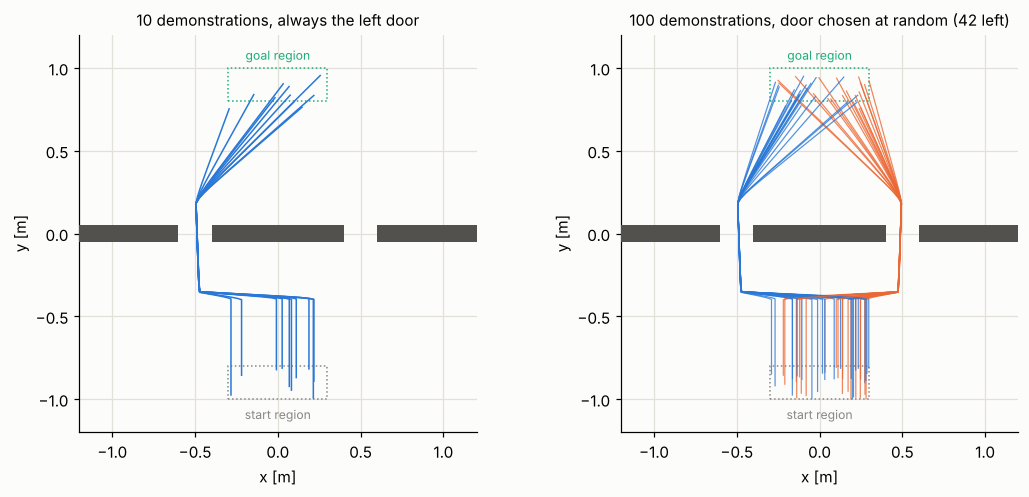

left-door data: 764 (obs, action) pairs | two-door data: 7547 pairs


In [3]:
LEFT = lambda rng: -0.5
BOTH = lambda rng: float(rng.choice([-0.5, 0.5]))
O_left, A_left, tr_left, _ = collect_demos(env, 10, np.random.default_rng(0), LEFT)
O_both, A_both, tr_both, d_both = collect_demos(env, 100, np.random.default_rng(0), BOTH)
R["n_left_samples"] = int(sum(len(a) for a in A_left))
R["n_both_samples"] = int(sum(len(a) for a in A_both))
R["n_both_left"] = int(sum(d < 0 for d in d_both))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
draw_cell(axs[0], env, "10 demonstrations, always the left door")
for tr in tr_left:
    axs[0].plot(tr[:, 0], tr[:, 1], color=BLUE, lw=1)
draw_cell(axs[1], env, f"100 demonstrations, door chosen at random ({R['n_both_left']} left)")
for tr, d in zip(tr_both[:40], d_both[:40]):
    axs[1].plot(tr[:, 0], tr[:, 1], color=BLUE if d < 0 else ORANGE, lw=0.8, alpha=0.8)
plt.tight_layout(); plt.show()
print(f"left-door data: {R['n_left_samples']} (obs, action) pairs | two-door data: {R['n_both_samples']} pairs")

## 3. Behaviour cloning

Behaviour cloning (BC) treats the demonstrations $\mathcal D=\{(o_i, a_i)\}$ as a supervised data set
and fits a policy $\pi_\theta(o)$ by regression:

$$\min_\theta \; \frac{1}{|\mathcal D|}\sum_{(o,a)\in\mathcal D} \big\| \pi_\theta(o) - a \big\|^2 .$$

That is the whole algorithm: an MLP, mean-squared error, Adam — Lecture 7's inverse-dynamics network
with different labels. The observation is standardised with the training-set mean and standard
deviation, as always.

In [4]:
def mlp(i, o, h=128, n_hidden=2):
    layers, d = [], i
    for _ in range(n_hidden):
        layers += [nn.Linear(d, h), nn.ReLU()]; d = h
    layers.append(nn.Linear(d, o))
    return nn.Sequential(*layers)


class Normalizer:
    '''Standardise observations with statistics of the training set.'''
    def __init__(self, X):
        self.mu = X.mean(0); self.sd = X.std(0) + 1e-3
    def __call__(self, X):
        return ((X - self.mu) / self.sd).astype(np.float32)


def train_bc(O, A, epochs=300, lr=1e-3, seed=0, h=128, batch=256):
    '''Behaviour cloning = supervised regression of the expert's action on the observation.'''
    torch.manual_seed(seed)
    X, Y = np.concatenate(O), np.concatenate(A)
    norm = Normalizer(X)
    Xt, Yt = torch.tensor(norm(X)), torch.tensor(Y)
    net = mlp(X.shape[1], ACT_DIM, h)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    n = len(Xt)
    for it in range(max(1, epochs * n // batch)):
        idx = torch.randint(0, n, (min(batch, n),), generator=g)
        loss = F.mse_loss(net(Xt[idx]), Yt[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        full = F.mse_loss(net(Xt), Yt).item()
    return net, norm, full


def net_policy(net, norm):
    def pol(o, s, t):
        with torch.no_grad():
            return net(torch.tensor(norm(o[None]))).numpy()[0]
    return pol

### 3.1 How well does it work, and what happens under disturbance?

Train on 5, 10, 25 and 50 left-door demonstrations; test on 200 new start/goal pairs, without and with
the test-time disturbance.

In [5]:
TEST_NOISE = 0.1          # the "real" cell: velocity disturbance, std 0.1 m/s per step
bc_rows, bc_samples = [], []
for N in (5, 10, 25, 50):
    O, A, _, _ = collect_demos(env, N, np.random.default_rng(0), LEFT)
    bc_samples.append(sum(len(a) for a in A))
    net, norm, loss = train_bc(O, A)
    clean, _ = evaluate(env, net_policy(net, norm), noise=0.0)
    noisy, res = evaluate(env, net_policy(net, norm), noise=TEST_NOISE)
    bc_rows.append((N, loss, clean["success"], noisy["success"], noisy["crash"], noisy["timeout"]))
    R[f"bc{N}_clean"], R[f"bc{N}_noisy"] = pct(clean["success"]), pct(noisy["success"])
    R[f"bc{N}_crash"], R[f"bc{N}_timeout"] = pct(noisy["crash"]), pct(noisy["timeout"])
    if N == 10:
        bc10, bc10_norm, bc10_res = net, norm, res
print(" demos  train MSE   success(no noise)  success(noise)  crash  timeout")
for N, loss, c, s, cr, to in bc_rows:
    print(f"{N:6d}  {loss:9.5f}   {100*c:14.1f} %  {100*s:12.1f} %  {100*cr:4.1f} %  {100*to:5.1f} %")

 demos  train MSE   success(no noise)  success(noise)  crash  timeout
     5    0.01785             47.5 %          56.0 %  11.0 %   33.0 %
    10    0.01296             91.5 %          81.0 %   8.5 %   10.5 %
    25    0.00880            100.0 %          94.0 %   0.5 %    5.5 %
    50    0.00575            100.0 %          97.0 %   1.0 %    2.0 %


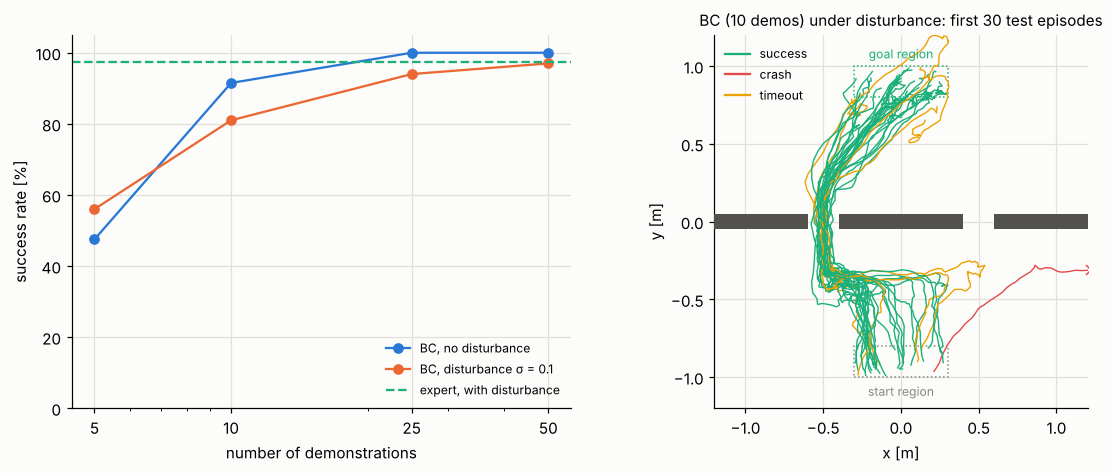

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1, 1.15]))
Ns = [r[0] for r in bc_rows]
axs[0].plot(Ns, [100 * r[2] for r in bc_rows], "o-", color=BLUE, label="BC, no disturbance")
axs[0].plot(Ns, [100 * r[3] for r in bc_rows], "o-", color=ORANGE, label=f"BC, disturbance σ = {TEST_NOISE}")
axs[0].axhline(R["expert_L_0.1"], color=AQUA, ls="--", label="expert, with disturbance")
axs[0].set_xscale("log"); axs[0].set_xticks(Ns); axs[0].set_xticklabels(Ns)
axs[0].xaxis.set_minor_formatter(NullFormatter())
axs[0].set_xlabel("number of demonstrations"); axs[0].set_ylabel("success rate [%]")
axs[0].set_ylim(0, 105); axs[0].legend(loc="lower right", fontsize=8)
draw_cell(axs[1], env, "BC (10 demos) under disturbance: first 30 test episodes")
col = {"success": AQUA, "crash": RED, "timeout": YELLOW}
for r in bc10_res[:30]:
    axs[1].plot(r["traj"][:, 0], r["traj"][:, 1], color=col[r["status"]], lw=0.9)
    if r["status"] == "crash":
        axs[1].plot(*r["traj"][-1], "x", color=RED, ms=6)
for k, c in col.items():
    axs[1].plot([], [], color=c, label=k)
axs[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

Read the table in two directions.

* **Down the columns: data helps.** With 5 demonstrations the policy succeeds only 47.5 % of
  the time even without disturbance; 25 are enough for 100.0 %.
* **Across the rows: disturbance hurts the learner far more than the expert.** At 10 demonstrations
  success falls from 91.5 % to 81.0 % (crashes 8.5 %, time-outs
  10.5 %), while the expert loses only 2.5 points. The learner reaches states the expert
  never visited — a little left of the line, or below the traverse height — and in those states its
  output is an extrapolation, not a correction.

(At 5 demonstrations the disturbance *raises* success, 47.5 → 56.0 %: that policy
mostly stalls, and noise sometimes knocks it out of the stall. A policy rescued by noise is not a
policy you can ship.)

**Compounding error.** Suppose the learner makes a mistake with probability $\varepsilon$ at each step
of a $T$-step task, measured *on the expert's state distribution*. Once it has made one, it is in a
state the data does not cover, and may keep erring until the end. Ross and Bagnell (2010) show that
the expected cost of BC can then grow as $O(\varepsilon T^2)$, against $O(\varepsilon T)$ for a learner
trained on its own state distribution. Long tasks and precise tasks — a 20 cm door, a connector — are
where BC breaks first.

### 3.2 Lower loss, worse robot: causal confusion

A natural "improvement" is to give the policy more information — here, the measured velocity, which
makes the state Markov (the servo lag means position alone does not determine the future). Train on
the *same* 25 demonstrations with and without it:

In [7]:
env_v = DoorReach(use_vel=True)
O25, A25, _, _ = collect_demos(env, 25, np.random.default_rng(0), LEFT)
O25v, A25v, _, _ = collect_demos(env_v, 25, np.random.default_rng(0), LEFT)   # same demos, + velocity
cc = {}
for name, e, O, A in (("without velocity", env, O25, A25), ("with velocity", env_v, O25v, A25v)):
    net, norm, loss = train_bc(O, A)
    clean, _ = evaluate(e, net_policy(net, norm), noise=0.0)
    noisy, _ = evaluate(e, net_policy(net, norm), noise=TEST_NOISE)
    cc[name] = (loss, clean, noisy)
    print(f"{name:17s} train MSE {loss:.5f} | success no noise {pct(clean['success']):5.1f} % "
          f"(timeouts {pct(clean['timeout']):4.1f} %) | with noise {pct(noisy['success']):5.1f} %")
R["cc_loss_novel"], R["cc_loss_vel"] = round(cc["without velocity"][0], 5), round(cc["with velocity"][0], 5)
R["cc_clean_novel"], R["cc_clean_vel"] = pct(cc["without velocity"][1]["success"]), pct(cc["with velocity"][1]["success"])
R["cc_to_vel"] = pct(cc["with velocity"][1]["timeout"])
R["cc_noisy_novel"], R["cc_noisy_vel"] = pct(cc["without velocity"][2]["success"]), pct(cc["with velocity"][2]["success"])

without velocity  train MSE 0.00880 | success no noise 100.0 % (timeouts  0.0 %) | with noise  94.0 %


with velocity     train MSE 0.00171 | success no noise   6.5 % (timeouts  3.0 %) | with noise   2.0 %


The velocity input lowers the training error about five-fold (0.0088 → 0.00171) and
destroys the robot: success falls from 100.0 % to 6.5 %.

The reason is the servo lag. In the demonstrations the velocity is a smoothed copy of the **previous
command**, so "output roughly what you are already doing" predicts the label very well. The network
learns that shortcut instead of the real cause — where the robot is relative to the door. In closed
loop the shortcut feeds itself: whatever the robot is doing, the policy keeps doing it. Most failures
are crashes — the robot rises straight past the traverse line into the wall, or keeps sliding sideways
past the door. De Haan et al. (2019) call this **causal confusion**;
Wen et al. (2020) call it the **copycat problem**. It is common in practice whenever the input
includes a history of proprioception or past actions.

Lessons: the training loss of an imitation policy is a poor guide to closed-loop performance — always
evaluate by **rolling the policy out**; and be careful with inputs that leak the previous action.
Remedies in the literature include dropping or noising such inputs, predicting action *chunks*
(§6.3), and weighting samples where the expert *changed* its action.

## 4. Fixing distribution shift: DAgger and DART

BC learns from the states the **expert** visits; the robot is then evaluated on the states the
**learner** visits. DAgger (Dataset Aggregation; Ross, Gordon and Bagnell, 2011) closes the gap:

1. train $\pi_1$ by BC on the demonstrations;
2. **run the learner** and record the states it visits;
3. ask the **expert** to label those states with the action it would have taken;
4. add them to the data set, retrain, repeat.

After a few rounds the data set covers the learner's own mistakes, and the error bound becomes linear
in $T$. The catch for real robots is step 3: the expert must label states it did not produce. With a
scripted or planner expert that is free; with a human it is done by letting the operator take over when
the robot drifts (HG-DAgger; Kelly et al., 2019) and recording the correction.

A cheaper alternative is **DART** (Laskey et al., 2017): perturb the robot *while the expert is
demonstrating* — inject noise into the executed command — but record the expert's clean action. The
expert's corrections are then in the data from the start.

In [8]:
def dagger(n_demos=10, iters=5, rollouts_per_iter=10, seed=0, door=-0.5):
    '''DAgger (Ross et al., 2011): run the LEARNER, ask the expert what it should have done
    in the states the learner actually visited, aggregate, retrain.'''
    rng = np.random.default_rng(seed)
    O, A, _, _ = collect_demos(env, n_demos, rng, lambda r: door)
    O, A = list(O), list(A)
    curve = []
    for it in range(iters + 1):
        net, norm, _ = train_bc(O, A)
        r, _ = evaluate(env, net_policy(net, norm), noise=TEST_NOISE)
        curve.append((it, sum(len(a) for a in A), r["success"]))
        if it == iters:
            break
        pol = net_policy(net, norm)
        for _ in range(rollouts_per_iter):
            ro = rollout(env, pol, rng, noise=TEST_NOISE, record=True)
            O.append(ro["obs"])
            A.append(np.array([expert_action(env, s, door) for s in ro["states"]]))   # expert relabels
    return np.array(curve), net, norm


t0 = time.time()
dag_curve, dag_net, dag_norm = dagger()
R["dagger_secs"] = round(time.time() - t0)
for it, n, s in dag_curve:
    print(f"DAgger iteration {int(it)}: {int(n):5d} labelled samples -> success {100*s:5.1f} %")
R["dag0"], R["dag1"], R["dag_last"] = pct(dag_curve[0, 2]), pct(dag_curve[1, 2]), pct(dag_curve[-1, 2])
R["dag_n1"], R["dag_n_last"] = int(dag_curve[1, 1]), int(dag_curve[-1, 1])

# DART: inject noise while the expert demonstrates; the label stays the expert's clean action
O, A, _, _ = collect_demos(env, 10, np.random.default_rng(0), LEFT, dart=0.3)
net, norm, _ = train_bc(O, A)
r_dart, _ = evaluate(env, net_policy(net, norm), noise=TEST_NOISE)
R["dart"] = pct(r_dart["success"]); R["dart_samples"] = int(sum(len(a) for a in A))
print(f"DART (10 demos, executed-action noise 0.3): success {R['dart']} % with {R['dart_samples']} samples")

DAgger iteration 0:   764 labelled samples -> success  81.0 %
DAgger iteration 1:  1596 labelled samples -> success  96.5 %
DAgger iteration 2:  2332 labelled samples -> success  97.0 %
DAgger iteration 3:  3150 labelled samples -> success  97.5 %
DAgger iteration 4:  4013 labelled samples -> success  99.5 %
DAgger iteration 5:  4857 labelled samples -> success  95.0 %


DART (10 demos, executed-action noise 0.3): success 96.5 % with 860 samples


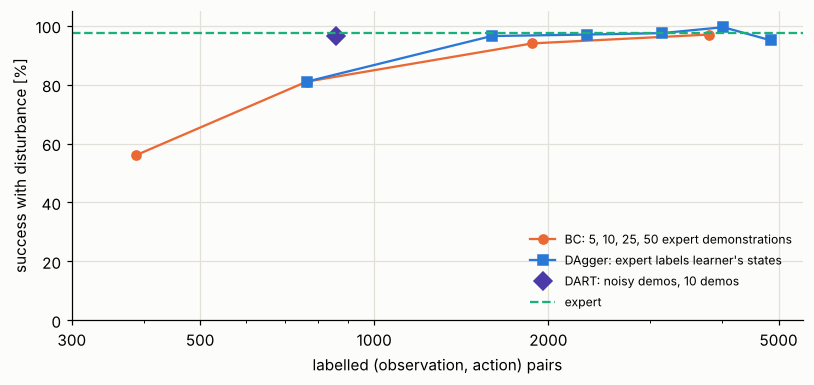

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(bc_samples, [100 * r[3] for r in bc_rows], "o-", color=ORANGE,
        label="BC: 5, 10, 25, 50 expert demonstrations")
ax.plot(dag_curve[:, 1], 100 * dag_curve[:, 2], "s-", color=BLUE, label="DAgger: expert labels learner's states")
ax.plot([R["dart_samples"]], [R["dart"]], "D", color=VIOLET, ms=8, label="DART: noisy demos, 10 demos")
ax.axhline(R["expert_L_0.1"], color=AQUA, ls="--", label="expert")
ax.set_xscale("log"); ax.set_xlabel("labelled (observation, action) pairs")
ax.set_xticks([300, 500, 1000, 2000, 5000]); ax.set_xticklabels(["300", "500", "1000", "2000", "5000"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_ylabel(f"success with disturbance [%]"); ax.set_ylim(0, 105); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

One round of DAgger — ten learner roll-outs relabelled by the expert — lifts the 10-demonstration
policy from 81.0 % to 96.5 % under disturbance, with 1,596 labelled pairs; plain BC needs about 25
demonstrations to reach a similar level (94.0 %). DART, with the same 10 demonstrations recorded
under noise, reaches 96.5 % with only 860 pairs and no extra expert queries. Later DAgger
rounds move between 95.0 % and 99.5 %: with 200 test episodes the standard error of a success
rate near 96 % is about 1.4 points, so those differences are noise.

What matters is **where** the data comes from, not only how much. More demonstrations of the same
clean behaviour do eventually work here (50 demos: 97.0 %), but recovery data is far cheaper.

## 5. Multimodal demonstrations

Now use the 100 demonstrations in which the operator chose a door at random. From the start region,
both "go left" and "go right" are correct. What does MSE regression do with two correct answers?

In [10]:
mse_net, mse_norm, _ = train_bc(O_both, A_both)
r_mse0, res_mse0 = evaluate(env, net_policy(mse_net, mse_norm), noise=0.0)
r_mse1, _ = evaluate(env, net_policy(mse_net, mse_norm), noise=TEST_NOISE)
R["mse_clean"], R["mse_clean_to"], R["mse_noisy"] = pct(r_mse0["success"]), pct(r_mse0["timeout"]), pct(r_mse1["success"])
print("MSE behaviour cloning on two-door data:")
print("  no disturbance:", {k: pct(v) for k, v in r_mse0.items()})
print("  disturbance   :", {k: pct(v) for k, v in r_mse1.items()})

# what does the network output on the traverse line?
xs = np.linspace(-0.6, 0.6, 121)
probe = np.array([env.obs(dict(p=np.array([x, -0.35]), v=np.zeros(2), g=np.array([0.0, 0.9]))) for x in xs])
with torch.no_grad():
    ux_mse = mse_net(torch.tensor(mse_norm(probe))).numpy()[:, 0]

MSE behaviour cloning on two-door data:
  no disturbance: {'success': 41.5, 'crash': 0.0, 'timeout': 58.5}
  disturbance   : {'success': 82.5, 'crash': 1.0, 'timeout': 16.5}


Without disturbance the MSE policy succeeds in only 41.5 % of episodes, and the rest are
**time-outs** (58.5 %): the robot rises to the traverse line and then hesitates. The minimiser
of squared error is the **conditional mean** $\mathbb E[a\mid o]$. Where half the demonstrations say
"left, full speed" and half say "right, full speed", the mean says "stand still". (Disturbance pushes
it off the tie, so it does better with noise, 82.5 % — again, not something to rely on.)

The fix is to learn the whole conditional **distribution** $p(a\mid o)$ and *sample* from it.

### 5.1 Mixture density network

A mixture density network (MDN; Bishop, 1994) outputs the parameters of a $K$-component Gaussian
mixture and is trained by maximum likelihood:

$$\pi_\theta(a\mid o)=\sum_{k=1}^K w_k(o)\,\mathcal N\!\big(a;\,\mu_k(o),\,\mathrm{diag}\,\sigma_k^2(o)\big),
\qquad \min_\theta\; -\log \pi_\theta(a\mid o).$$

At run time we pick a component with probability $w_k$ and sample from it. Same body as BC, a wider
output layer, a different loss.

In [11]:
class MDN(nn.Module):
    '''Mixture density network (Bishop, 1994): the policy outputs a K-component Gaussian mixture.'''
    def __init__(self, K=5, h=128):
        super().__init__()
        self.K = K
        self.body = nn.Sequential(nn.Linear(OBS_DIM, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.head = nn.Linear(h, K * (2 * ACT_DIM + 1))

    def forward(self, x):
        z = self.head(self.body(x)); K, D = self.K, ACT_DIM
        logit = z[:, :K]
        mu = z[:, K:K + K * D].view(-1, K, D)
        log_sd = z[:, K + K * D:].view(-1, K, D).clamp(-5, 1)
        return logit, mu, log_sd

    def nll(self, x, y):
        logit, mu, log_sd = self(x)
        lp = (-0.5 * (((y[:, None] - mu) / log_sd.exp()) ** 2) - log_sd).sum(-1) - ACT_DIM * 0.5 * np.log(2 * np.pi)
        return -torch.logsumexp(F.log_softmax(logit, -1) + lp, -1).mean()


def train_mdn(O, A, K=5, epochs=300, lr=1e-3, seed=0, batch=256):
    torch.manual_seed(seed)
    X, Y = np.concatenate(O), np.concatenate(A)
    norm = Normalizer(X)
    Xt, Yt = torch.tensor(norm(X)), torch.tensor(Y)
    net = MDN(K); opt = torch.optim.Adam(net.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    for it in range(epochs * len(Xt) // batch):
        idx = torch.randint(0, len(Xt), (batch,), generator=g)
        loss = net.nll(Xt[idx], Yt[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    return net, norm


def mdn_policy(net, norm, seed=0):
    gen = torch.Generator().manual_seed(seed)
    def pol(o, s, t):
        with torch.no_grad():
            logit, mu, log_sd = net(torch.tensor(norm(o[None])))
            k = torch.multinomial(F.softmax(logit, -1), 1, generator=gen)[0, 0]
            return (mu[0, k] + log_sd[0, k].exp() * torch.randn(ACT_DIM, generator=gen)).numpy()
    return pol


def reversals(res):
    '''Mean number of left/right direction changes while on the traverse line: hesitation.'''
    out = []
    for r in res:
        tr = r["traj"]; m = (tr[:-1, 1] > -0.45) & (tr[:-1, 1] < -0.25)
        dx = np.diff(tr[:, 0])[m]; dx = dx[np.abs(dx) > 0.003]
        out.append(np.sum(np.diff(np.sign(dx)) != 0))
    return float(np.mean(out))


t0 = time.time()
mdn_net, mdn_norm = train_mdn(O_both, A_both)
R["mdn_secs"] = round(time.time() - t0)
r_mdn0, res_mdn0 = evaluate(env, mdn_policy(mdn_net, mdn_norm), noise=0.0)
r_mdn1, _ = evaluate(env, mdn_policy(mdn_net, mdn_norm), noise=TEST_NOISE)
R["mdn_clean"], R["mdn_noisy"], R["mdn_rev"] = pct(r_mdn0["success"]), pct(r_mdn1["success"]), round(reversals(res_mdn0), 2)
print(f"MDN trained in {R['mdn_secs']} s | success no noise {R['mdn_clean']} %, with noise {R['mdn_noisy']} %"
      f" | direction reversals on the traverse line {R['mdn_rev']}")
with torch.no_grad():
    logit, mu, _ = mdn_net(torch.tensor(mdn_norm(probe)))
    w_mdn = F.softmax(logit, -1).numpy(); mux_mdn = mu[:, :, 0].numpy()

MDN trained in 16 s | success no noise 98.5 %, with noise 77.5 % | direction reversals on the traverse line 4.16


The MDN fixes the stall: 98.5 % success without disturbance. But it re-samples its mode
at **every** step, and on the traverse line the observation does not say which way it was going (we
removed velocity in §3.2), so it hesitates: 4.16 left/right reversals per episode on the traverse
line. Under disturbance its success drops to 77.5 %.

### 5.2 Diffusion policy with action chunks

**Diffusion Policy** (Chi et al., 2023) makes two changes, and both matter.

**(a) A diffusion model for $p(a\mid o)$.** A denoising diffusion model (Ho et al., 2020) learns to
reverse a fixed noising process. Training: take a demonstrated action $a^0$, pick a noise level
$k$, form $a^k = \sqrt{\bar\alpha_k}\,a^0 + \sqrt{1-\bar\alpha_k}\,\epsilon$, and train a network to
predict the noise,

$$\min_\theta\; \mathbb E_{a^0,k,\epsilon}\,\big\|\epsilon_\theta(a^k, k, o) - \epsilon\big\|^2 .$$

Sampling: start from Gaussian noise and apply the learned denoiser $K$ = 50 times. The loss is an MSE,
but on the *noise*, so the model never averages the modes: each sample ends in one of them.

**(b) Predict a chunk of actions.** Instead of one action, the model generates the next $H$ = 8
(0.8 s) as one 16-dimensional sample, and the robot executes the first $n_\text{exec}$ before
re-planning (receding horizon, as in model-predictive control). A chunk is a commitment: one sample
contains one consistent route. Action chunking was introduced for robot imitation by ACT
(Zhao et al., 2023), which also showed that it reduces compounding error by making the effective
horizon $H$ times shorter.

In [12]:
def make_chunks(O, A, H):
    '''Training pairs (o_t, [a_t, ..., a_{t+H-1}]); the end of each demo is padded.'''
    X, Y = [], []
    for o, a in zip(O, A):
        pad = np.concatenate([a, np.repeat(a[-1:], H, 0)])
        for t in range(len(a)):
            X.append(o[t]); Y.append(pad[t:t + H].reshape(-1))
    return np.array(X, np.float32), np.array(Y, np.float32)


class Denoiser(nn.Module):
    '''eps_theta(a^k, k, o): predicts the noise that was added to a clean action chunk.'''
    def __init__(self, a_dim, K, h=256):
        super().__init__()
        self.k_emb = nn.Embedding(K, 32)
        self.net = nn.Sequential(nn.Linear(a_dim + 32 + OBS_DIM, h), nn.SiLU(),
                                 nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(),
                                 nn.Linear(h, a_dim))
    def forward(self, a, k, o):
        return self.net(torch.cat([a, self.k_emb(k), o], -1))


class DDPM:
    '''Denoising diffusion (Ho et al., 2020) with a cosine noise schedule (Nichol & Dhariwal, 2021).'''
    def __init__(self, K=50):
        self.K = K
        t = torch.linspace(0, 1, K + 1)
        f = torch.cos((t + 0.008) / 1.008 * np.pi / 2) ** 2
        self.beta = (1 - f[1:] / f[:-1]).clamp(max=0.999)
        self.alpha = 1 - self.beta
        self.abar = torch.cumprod(self.alpha, 0)

    def loss(self, net, a0, o, gen):
        k = torch.randint(0, self.K, (len(a0),), generator=gen)
        eps = torch.randn(a0.shape, generator=gen)
        ab = self.abar[k][:, None]
        return F.mse_loss(net(ab.sqrt() * a0 + (1 - ab).sqrt() * eps, k, o), eps)

    @torch.no_grad()
    def sample(self, net, o, a_dim, gen):
        a = torch.randn((len(o), a_dim), generator=gen)              # start from pure noise
        for k in reversed(range(self.K)):
            eps = net(a, torch.full((len(o),), k, dtype=torch.long), o)
            a = (a - self.beta[k] / (1 - self.abar[k]).sqrt() * eps) / self.alpha[k].sqrt()
            if k > 0:
                var = self.beta[k] * (1 - self.abar[k - 1]) / (1 - self.abar[k])
                a = a + var.sqrt() * torch.randn(a.shape, generator=gen)
        return a.clamp(-1.5, 1.5)


def train_diffusion(O, A, H=8, iters=12_000, lr=1e-3, seed=0, batch=256):
    torch.manual_seed(seed)
    X, Y = make_chunks(O, A, H)
    norm = Normalizer(X)
    Xt, Yt = torch.tensor(norm(X)), torch.tensor(Y)
    ddpm = DDPM(); net = Denoiser(H * ACT_DIM, ddpm.K)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters)
    gen = torch.Generator().manual_seed(seed)
    for it in range(iters):
        idx = torch.randint(0, len(Xt), (batch,), generator=gen)
        loss = ddpm.loss(net, Yt[idx], Xt[idx], gen)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    net.eval()
    return dict(net=net, norm=norm, ddpm=ddpm, H=H)


def diffusion_policy(model, n_exec, seed=0):
    '''Receding horizon: sample a chunk of H actions, execute the first n_exec, re-plan.'''
    gen = torch.Generator().manual_seed(seed)
    buf = []
    def pol(o, s, t):
        nonlocal buf
        if t == 0:
            buf = []
        if not buf:
            chunk = model["ddpm"].sample(model["net"], torch.tensor(model["norm"](o[None])),
                                         model["H"] * ACT_DIM, gen)
            buf = list(chunk.numpy().reshape(model["H"], ACT_DIM)[:n_exec])
        return buf.pop(0)
    return pol


t0 = time.time()
dp = train_diffusion(O_both, A_both, H=8)
R["diff_secs"] = round(time.time() - t0)
print(f"diffusion policy (chunk H = 8, 50 denoising steps) trained in {R['diff_secs']} s")

diffusion policy (chunk H = 8, 50 denoising steps) trained in 35 s


Evaluate the same trained model with three execution horizons: re-plan every step
($n_\text{exec}$ = 1), execute half the chunk (4), or the whole chunk open loop (8). Diffusion sampling
costs 50 network calls per decision, so we use 100 test episodes per setting here (standard error about
3 points).

In [13]:
N_DIFF = 100              # diffusion sampling is slow on a CPU: 100 test episodes per setting
diff_rows = {}
for n_exec in (1, 4, 8):
    t0 = time.time()
    r0, res0 = evaluate(env, diffusion_policy(dp, n_exec), n=N_DIFF, noise=0.0)
    r1, _ = evaluate(env, diffusion_policy(dp, n_exec), n=N_DIFF, noise=TEST_NOISE)
    diff_rows[n_exec] = (r0, r1, reversals(res0), res0)
    R[f"dp{n_exec}_clean"], R[f"dp{n_exec}_noisy"] = pct(r0["success"]), pct(r1["success"])
    R[f"dp{n_exec}_rev"], R[f"dp{n_exec}_crash"] = round(reversals(res0), 2), pct(r1["crash"])
    print(f"execute {n_exec} of 8: success no noise {pct(r0['success']):5.1f} %, with noise {pct(r1['success']):5.1f} % "
          f"(crash {pct(r1['crash']):4.1f} %) | reversals {reversals(res0):.2f} | {time.time()-t0:.0f} s")

execute 1 of 8: success no noise 100.0 %, with noise  88.0 % (crash 11.0 %) | reversals 3.04 | 77 s


execute 4 of 8: success no noise 100.0 %, with noise  90.0 % (crash  7.0 %) | reversals 1.32 | 20 s


execute 8 of 8: success no noise 100.0 %, with noise  77.0 % (crash 18.0 %) | reversals 0.56 | 10 s


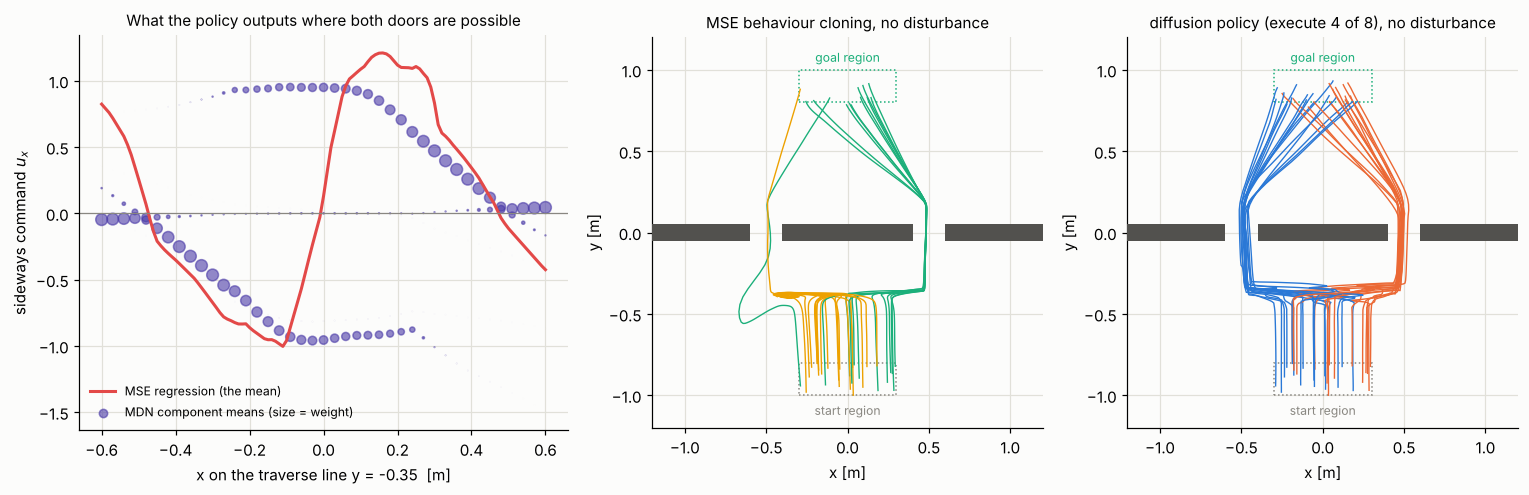

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
ax = axs[0]
ax.plot(xs, ux_mse, color=RED, lw=2, label="MSE regression (the mean)")
for k in range(mdn_net.K):
    ax.scatter(xs[::3], mux_mdn[::3, k], s=60 * w_mdn[::3, k], color=VIOLET, alpha=0.6,
               label="MDN component means (size = weight)" if k == 0 else None)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel("x on the traverse line y = -0.35  [m]"); ax.set_ylabel("sideways command $u_x$")
ax.set_title("What the policy outputs where both doors are possible", fontsize=10)
ax.legend(fontsize=8, loc="lower left")
draw_cell(axs[1], env, "MSE behaviour cloning, no disturbance")
for r in res_mse0[:30]:
    axs[1].plot(r["traj"][:, 0], r["traj"][:, 1], color={"success": AQUA, "crash": RED, "timeout": YELLOW}[r["status"]], lw=0.9)
draw_cell(axs[2], env, "diffusion policy (execute 4 of 8), no disturbance")
for r in diff_rows[4][3][:30]:
    tr = r["traj"]; above = np.flatnonzero(tr[:, 1] > 0)
    c = RED if len(above) == 0 else (BLUE if tr[above[0], 0] < 0 else ORANGE)
    axs[2].plot(tr[:, 0], tr[:, 1], color=c, lw=0.9)
plt.tight_layout(); plt.show()

The left panel shows *why*: on the traverse line, the MSE network's sideways command (red) passes
through zero between the doors, while the MDN keeps two separate components, one pointing each way,
and shifts their weights as the robot moves.

| policy | success, no disturbance | success, disturbance | reversals on traverse line |
|---|---|---|---|
| MSE behaviour cloning | 41.5 % | 82.5 % | — |
| MDN, re-sampled every step | 98.5 % | 77.5 % | 4.16 |
| diffusion, execute 1 of 8 | 100.0 % | 88.0 % | 3.04 |
| diffusion, execute 4 of 8 | 100.0 % | 90.0 % | 1.32 |
| diffusion, execute 8 of 8 | 100.0 % | 77.0 % | 0.56 |

* Every distributional policy solves the clean task; the MSE policy does not.
* **Longer execution, less hesitation**: reversals fall from 3.04 to 1.32 to 0.56 as
  the robot commits to more of each chunk.
* **But open-loop execution cannot react**: executing the whole chunk gives the worst disturbance
  result (77.0 %, 18.0 % crashes), because 0.8 s of drift goes uncorrected next to a wall.
  Executing half a chunk balances commitment and feedback (90.0 %). ACT handles the same
  trade-off with *temporal ensembling* — averaging overlapping chunks.

## 6. Conditioning, pre-training and fine-tuning: robot foundation models in miniature

### 6.1 Tell the robot which mode you want

Sampling a mode at random is fine if any mode will do. Usually it will not: the operator *means* a
specific door, part or bin. The fix is to give the policy that information as an input — a goal
image, a target pose, or a sentence. Below, a single policy is trained on 300 demonstrations across
**random layouts** (two doors placed anywhere in $[-0.85,-0.25]$ and $[0.25,0.85]$), each with one of
two instructions: *"go through the left door"* or *"go through the right door"*. The instruction is
embedded as a learned 16-D vector — in a real VLA it would be the output of a language model — and
concatenated with the observation. We compare with the same network trained on the same data with the
instruction removed, and test on 200 **held-out** layouts with disturbance.

In [15]:
def random_layout(rng):
    return (rng.uniform(-0.85, -0.25), rng.uniform(0.25, 0.85))


def instructed_demos(n, rng, dart=0.3, **robot):
    '''One demo per random layout; the instruction says which door to use.'''
    O, A, K = [], [], []
    for _ in range(n):
        e = DoorReach(doors=random_layout(rng), **robot); k = int(rng.integers(2))
        o, a, _, _ = collect_demos(e, 1, rng, lambda r, d=e.doors[k]: d, dart=dart)
        O += o; A += a; K.append(k)
    return O, A, K


class InstructedPolicy(nn.Module):
    '''A toy vision-language-action policy: an instruction token is embedded and joined to
    the observation; an MLP "action head" maps both to a command.'''
    def __init__(self, n_instr=2, h=128, e=16):
        super().__init__()
        self.emb = nn.Embedding(n_instr, e)
        self.trunk = nn.Sequential(nn.Linear(OBS_DIM + e, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.head = nn.Linear(h, ACT_DIM)
    def forward(self, x, k):
        return self.head(self.trunk(torch.cat([x, self.emb(k)], -1)))


def train_instructed(O, A, K, epochs=200, lr=1e-3, seed=0, batch=256, net=None, norm=None, params=None):
    torch.manual_seed(seed)
    X, Y = np.concatenate(O), np.concatenate(A)
    Kc = np.concatenate([np.full(len(o), k) for o, k in zip(O, K)])
    norm = norm or Normalizer(X)
    Xt, Yt, Kt = torch.tensor(norm(X)), torch.tensor(Y), torch.tensor(Kc, dtype=torch.long)
    net = net or InstructedPolicy()
    opt = torch.optim.Adam(params if params is not None else net.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    n = len(Xt)
    for it in range(max(1, epochs * n // batch)):
        idx = torch.randint(0, n, (min(batch, n),), generator=g)
        loss = F.mse_loss(net(Xt[idx], Kt[idx]), Yt[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    return net, norm


def instructed_policy(net, norm, k):
    kt = torch.tensor([k])
    def pol(o, s, t):
        with torch.no_grad():
            return net(torch.tensor(norm(o[None])), kt).numpy()[0]
    return pol


def eval_instructed(make_policy, n=200, seed=2000, **robot):
    '''Held-out layouts.  Returns (success rate, rate of success through the INSTRUCTED door).'''
    rng = np.random.default_rng(seed); succ = obeyed = 0
    for _ in range(n):
        e = DoorReach(doors=random_layout(rng), **robot); k = int(rng.integers(2))
        r = rollout(e, make_policy(k), rng, noise=TEST_NOISE)
        tr = r["traj"]; above = np.flatnonzero(tr[:, 1] > 0)
        door_used = int(np.argmin(np.abs(e.doors - tr[above[0], 0]))) if len(above) else -1
        succ += r["status"] == "success"; obeyed += (r["status"] == "success") and door_used == k
    return succ / n, obeyed / n


t0 = time.time()
O_pre, A_pre, K_pre = instructed_demos(300, np.random.default_rng(0))
base, base_norm = train_instructed(O_pre, A_pre, K_pre)
R["pre_samples"], R["pre_secs"] = int(sum(len(a) for a in A_pre)), round(time.time() - t0)
s, ob = eval_instructed(lambda k: instructed_policy(base, base_norm, k))
R["instr_succ"], R["instr_obey"] = pct(s), pct(ob)
blind, blind_norm, _ = train_bc(O_pre, A_pre, epochs=200)            # same data, instruction dropped
s, ob = eval_instructed(lambda k: net_policy(blind, blind_norm))
R["blind_succ"], R["blind_obey"] = pct(s), pct(ob)
print(f"pre-training set: 300 layouts, {R['pre_samples']} samples, {R['pre_secs']} s")
print(f"instruction-conditioned: success {R['instr_succ']} %, through the instructed door {R['instr_obey']} %")
print(f"no instruction         : success {R['blind_succ']} %, through the instructed door {R['blind_obey']} %")

pre-training set: 300 layouts, 25708 samples, 30 s
instruction-conditioned: success 98.5 %, through the instructed door 98.5 %
no instruction         : success 90.5 %, through the instructed door 47.0 %


The instruction-conditioned policy reaches the goal through the **instructed** door in 98.5 %
of held-out layouts. Without the instruction the policy still reaches the goal (90.5 %; it has
learned to break ties), but uses the door we wanted only 47.0 % of the time — chance. Note that
conditioning also removes the multimodality: given the instruction, the demonstrations are unimodal
again, and plain MSE works.

### 6.2 A new robot: pre-train, then fine-tune

Now the policy must run on a **different robot**: its base is mounted rotated by 40°, so every command
is interpreted in a rotated frame, and its axes are slower ($v_\text{max}$ = 0.45 m/s, $\tau$ = 0.25 s).
This is the *cross-embodiment* problem every foundation model faces. We have only 5, 10 or 20
demonstrations on the new robot and compare three options:

* **from scratch** — train a fresh policy on the new demonstrations only;
* **fine-tune all** — start from the pre-trained policy and update every weight (lower learning rate);
* **fine-tune the action head** — freeze the trunk and the instruction embedding, re-train only the
  last linear layer, the analogue of attaching a new "action head" for a new embodiment.

In [16]:
NEW_ROBOT = dict(mount_deg=40.0, tau=0.25, vmax=0.45)     # rotated base, slower, softer servo
rng = np.random.default_rng(5); ok = 0
for _ in range(200):
    e = DoorReach(doors=random_layout(rng), **NEW_ROBOT); d = e.doors[int(rng.integers(2))]
    ok += rollout(e, lambda o, s, t: expert_action(e, s, d), rng, noise=TEST_NOISE)["status"] == "success"
R["new_expert"] = pct(ok / 200)
R["zero_shot"] = pct(eval_instructed(lambda k: instructed_policy(base, base_norm, k), **NEW_ROBOT)[1])
print(f"new robot: expert {R['new_expert']} % | pre-trained policy zero-shot {R['zero_shot']} %")

ft_rows = []
for N in (5, 10, 20):
    O_n, A_n, K_n = instructed_demos(N, np.random.default_rng(7), **NEW_ROBOT)
    scratch, sn = train_instructed(O_n, A_n, K_n, epochs=300)
    full = copy.deepcopy(base)
    full, _ = train_instructed(O_n, A_n, K_n, epochs=300, net=full, norm=base_norm, lr=3e-4)
    head = copy.deepcopy(base)
    head, _ = train_instructed(O_n, A_n, K_n, epochs=300, net=head, norm=base_norm, params=head.head.parameters())
    row = [N] + [pct(eval_instructed(lambda k, m=m, nn_=nn_: instructed_policy(m, nn_, k), **NEW_ROBOT)[1])
                 for m, nn_ in ((scratch, sn), (full, base_norm), (head, base_norm))]
    ft_rows.append(row)
    R[f"ft{N}_scratch"], R[f"ft{N}_full"], R[f"ft{N}_head"] = row[1:]
    print(f"{N:3d} new-robot demos | from scratch {row[1]:5.1f} % | fine-tune all {row[2]:5.1f} % | "
          f"fine-tune action head only {row[3]:5.1f} %")

new robot: expert 93.0 % | pre-trained policy zero-shot 2.5 %


  5 new-robot demos | from scratch  12.0 % | fine-tune all  64.0 % | fine-tune action head only  64.5 %


 10 new-robot demos | from scratch  46.5 % | fine-tune all  76.5 % | fine-tune action head only  69.5 %


 20 new-robot demos | from scratch  72.5 % | fine-tune all  80.5 % | fine-tune action head only  88.0 %


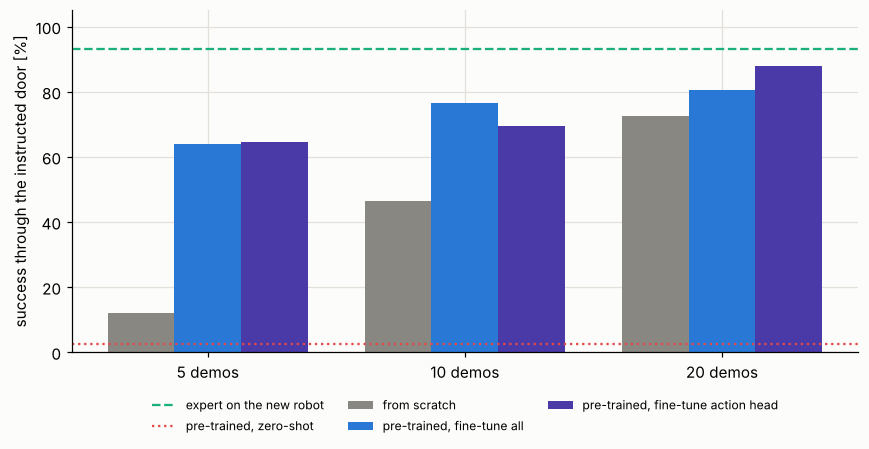

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = 0.26; xx = np.arange(len(ft_rows))
for j, (lab, c) in enumerate((("from scratch", GREY), ("pre-trained, fine-tune all", BLUE),
                              ("pre-trained, fine-tune action head", VIOLET))):
    ax.bar(xx + (j - 1) * w, [r[j + 1] for r in ft_rows], w, color=c, label=lab)
ax.axhline(R["new_expert"], color=AQUA, ls="--", label="expert on the new robot")
ax.axhline(R["zero_shot"], color=RED, ls=":", label="pre-trained, zero-shot")
ax.set_xticks(xx); ax.set_xticklabels([f"{r[0]} demos" for r in ft_rows])
ax.set_ylabel("success through the instructed door [%]"); ax.set_ylim(0, 105)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout(); plt.show()

* **Zero-shot transfer fails** (2.5 %): a 40° rotation of the action frame is not something the
  pre-trained policy could have guessed.
* **Pre-training pays off most when new data is scarcest.** With 5 demonstrations, fine-tuning reaches
  64.0 % (all weights) or 64.5 % (head only), against 12.0 % from scratch. With 20
  demonstrations from-scratch training catches up partly (72.5 %) but the fine-tuned head is
  still better (88.0 %; the new-robot expert itself scores 93.0 %).
* **Re-training only the head works** because the trunk already encodes *where the doors are and which
  one was asked for*; only the mapping to this robot's commands changed. That is the logic of
  embodiment-specific action heads and of parameter-efficient fine-tuning (LoRA) in real VLAs.

### 6.3 The real thing: vision-language-action models

| year | development | why it matters for robots |
|---|---|---|
| 1989 | ALVINN (Pomerleau) | behaviour cloning from camera to steering, and the first report of distribution shift |
| 2011 | DAgger (Ross, Gordon, Bagnell) | interactive data collection with a linear error bound |
| 2016 | GAIL (Ho & Ermon) | adversarial imitation: learn a reward-like discriminator, then do RL |
| 2022 | RT-1 (Brohan et al.) | a transformer trained on ~130k real demonstrations across 700+ tasks |
| 2023 | ACT / ALOHA (Zhao et al.); Diffusion Policy (Chi et al.) | action chunks and diffusion heads; fine bimanual skills from ~50 demos |
| 2023 | RT-2 (Brohan et al.) | a web-pretrained vision-language model fine-tuned to output action tokens: the first VLA |
| 2023–24 | Open X-Embodiment (Open X-Embodiment Collab.); DROID (Khazatsky et al.) | pooled datasets: ~1M episodes from 22 robot types; 76k episodes in 564 scenes |
| 2024 | Octo; OpenVLA (Kim et al.) | open-source generalist policies; OpenVLA is a 7B VLA fine-tunable with LoRA |
| 2024 | π0 (Black et al.) | a VLM backbone plus a flow-matching action expert producing 50-step action chunks |
| 2025 | π0.5; GR00T N1; Gemini Robotics | open-world generalisation, humanoids, and VLAs built on frontier multimodal models |
| 2024–25 | LeRobot (Hugging Face), SmolVLA | open tooling: teleoperation, data format, ACT/diffusion/VLA training on a single GPU |

How the ideas of this notebook appear in a VLA:

| this notebook | a vision-language-action model |
|---|---|
| 6 numbers of state | camera images + joint angles |
| instruction token, 16-D embedding | free text through a pretrained language model |
| 2 × 128 MLP | 0.5–7 B parameter vision-language backbone |
| MDN / diffusion on an 8-step chunk | action tokens, or a diffusion / flow-matching head on 10–50-step chunks |
| 300 demos, one robot | 10⁵–10⁶ episodes, tens of robot types |
| fine-tune head on 5–20 demos | fine-tune (often LoRA) on 50–500 demos of the new task or robot |

*This field moves monthly; check the latest releases before teaching from this table.*

## 7. Protocol — what to remember

1. **Imitation learning is supervised learning, judged in closed loop.** Validation loss ranks models
   badly; always measure success by rolling the policy out, with disturbances.
2. **Expect compounding error.** The longer and more precise the task, the more recovery data you need.
3. **Collect recovery data on purpose**: DAgger-style operator take-overs, or noise injection while
   demonstrating (DART). It is cheaper than more clean demonstrations.
4. **Beware inputs that leak the previous action** (velocity, action history): causal confusion.
5. **Check your demonstrations for multimodality.** Several operators, or one inconsistent operator,
   means MSE will average. Use a distributional head: MDN, discretised tokens, diffusion, flow matching.
6. **Predict action chunks and execute part of each** — commitment without losing feedback.
7. **Condition on what disambiguates the task** — goal, target object, instruction.
8. **Start from a pre-trained policy when one exists**, and fine-tune with the smallest change that
   works (an action head, LoRA) on demonstrations from *your* robot.
9. **Report robotics metrics**: success, crash (collision) rate, time-outs, hesitation — on held-out
   layouts.

## 8. Exercises

1. **Compounding error vs horizon.** Move the goal region to $y\in[1.0,1.15]$ and the wall to
   $y=0.2$ to lengthen the task. How does the gap between BC with and without disturbance change?
2. **Causal confusion, fixed.** Keep the velocity input but add Gaussian noise (σ = 0.2 m/s) to it during
   training only. Does closed-loop success recover? What about *dropout* on that input?
3. **DAgger with a human-like expert.** Make the expert label only states within 10 cm of its own
   path (an operator cannot judge states far from the task) and treat the rest as unlabelled. How much
   of DAgger's gain survives?
4. **Mixture size.** Train the MDN with $K$ = 1, 2 and 5. Which value is the smallest that removes the
   stall, and why is $K$ = 1 the same as MSE?
5. **Temporal ensembling.** Re-plan every step but average the overlapping predictions of the last
   8 chunks with exponential weights (as in ACT). Compare success and reversals with $n_\text{exec}$ = 4.
6. **Fewer denoising steps.** Sample the diffusion policy with 10 instead of 50 steps by skipping
   steps (DDIM, Song et al., 2021). Plot success against decision time.
7. **A third instruction.** Add *"use the nearer door"*. What must change in the expert, the data and
   the network? Test on layouts where the two doors are almost equally near.
8. **LoRA.** Replace "fine-tune the head" with a rank-2 low-rank update of each trunk layer. Compare
   with full and head-only fine-tuning at 5 demonstrations.

## 9. References

* D. A. Pomerleau, "ALVINN: an autonomous land vehicle in a neural network," NeurIPS 1988 (published 1989).
* S. Ross and J. A. Bagnell, "Efficient reductions for imitation learning," AISTATS 2010.
* S. Ross, G. Gordon, J. A. Bagnell, "A reduction of imitation learning and structured prediction to
  no-regret online learning" (DAgger), AISTATS 2011.
* M. Laskey, J. Lee, R. Fox, A. Dragan, K. Goldberg, "DART: noise injection for robust imitation
  learning," CoRL 2017.
* M. Kelly, C. Sidrane, K. Driggs-Campbell, M. J. Kochenderfer, "HG-DAgger: interactive imitation
  learning with human experts," ICRA 2019.
* P. de Haan, D. Jayaraman, S. Levine, "Causal confusion in imitation learning," NeurIPS 2019.
* C. Wen, J. Lin, T. Darrell, D. Jayaraman, Y. Gao, "Fighting copycat agents in behavioral cloning from
  observation histories," NeurIPS 2020.
* C. M. Bishop, "Mixture density networks," Aston University technical report NCRG/94/004, 1994.
* J. Ho and S. Ermon, "Generative adversarial imitation learning," NeurIPS 2016.
* J. Ho, A. Jain, P. Abbeel, "Denoising diffusion probabilistic models," NeurIPS 2020.
* A. Nichol and P. Dhariwal, "Improved denoising diffusion probabilistic models," ICML 2021.
* J. Song, C. Meng, S. Ermon, "Denoising diffusion implicit models," ICLR 2021.
* C. Chi et al., "Diffusion Policy: visuomotor policy learning via action diffusion," RSS 2023.
* T. Z. Zhao, V. Kumar, S. Levine, C. Finn, "Learning fine-grained bimanual manipulation with low-cost
  hardware" (ACT / ALOHA), RSS 2023.
* A. Brohan et al., "RT-1: robotics transformer for real-world control at scale," RSS 2023.
* A. Brohan et al., "RT-2: vision-language-action models transfer web knowledge to robotic control,"
  CoRL 2023.
* Open X-Embodiment Collaboration, "Open X-Embodiment: robotic learning datasets and RT-X models," ICRA 2024.
* A. Khazatsky et al., "DROID: a large-scale in-the-wild robot manipulation dataset," RSS 2024.
* Octo Model Team, "Octo: an open-source generalist robot policy," RSS 2024.
* M. J. Kim et al., "OpenVLA: an open-source vision-language-action model," CoRL 2024.
* K. Black et al., "π0: a vision-language-action flow model for general robot control," arXiv:2410.24164, 2024.
* Physical Intelligence, "π0.5: a vision-language-action model with open-world generalization,"
  arXiv:2504.16054, 2025.
* NVIDIA, "GR00T N1: an open foundation model for generalist humanoid robots," arXiv:2503.14734, 2025.
* Gemini Robotics Team, "Gemini Robotics: bringing AI into the physical world," arXiv:2503.20020, 2025.
* M. Shukor et al., "SmolVLA: a vision-language-action model for affordable and efficient robotics,"
  arXiv:2506.01844, 2025.
* LeRobot documentation: https://huggingface.co/docs/lerobot

In [18]:
R["total_minutes"] = round((time.time() - T_START) / 60, 1)
print(f"notebook ran in {R['total_minutes']} min")
print(json.dumps(R))

notebook ran in 5.5 min
{"expert_L_0.0": 100.0, "expert_L_0.1": 97.5, "expert_R_0.0": 100.0, "expert_R_0.1": 98.5, "n_left_samples": 764, "n_both_samples": 7547, "n_both_left": 42, "bc5_clean": 47.5, "bc5_noisy": 56.0, "bc5_crash": 11.0, "bc5_timeout": 33.0, "bc10_clean": 91.5, "bc10_noisy": 81.0, "bc10_crash": 8.5, "bc10_timeout": 10.5, "bc25_clean": 100.0, "bc25_noisy": 94.0, "bc25_crash": 0.5, "bc25_timeout": 5.5, "bc50_clean": 100.0, "bc50_noisy": 97.0, "bc50_crash": 1.0, "bc50_timeout": 2.0, "cc_loss_novel": 0.0088, "cc_loss_vel": 0.00171, "cc_clean_novel": 100.0, "cc_clean_vel": 6.5, "cc_to_vel": 3.0, "cc_noisy_novel": 94.0, "cc_noisy_vel": 2.0, "dagger_secs": 30, "dag0": 81.0, "dag1": 96.5, "dag_last": 95.0, "dag_n1": 1596, "dag_n_last": 4857, "dart": 96.5, "dart_samples": 860, "mse_clean": 41.5, "mse_clean_to": 58.5, "mse_noisy": 82.5, "mdn_secs": 16, "mdn_clean": 98.5, "mdn_noisy": 77.5, "mdn_rev": 4.16, "diff_secs": 35, "dp1_clean": 100.0, "dp1_noisy": 88.0, "dp1_rev": 3.04, 

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>